# Indian Paint Industry: Annual Revenue Forecasting with Machine Learning

## Problem Statement
> **Can we use historical financial and operational data of Indian paint companies to predict their future financial performance, particularly next-period/year revenue?**

### Industry Context & Economic Thesis
The Indian decorative and industrial paints market is an oligopoly dominated by four key players:
1. **Asian Paints** (Market leader, ~30,000+ Cr revenue)
2. **Berger Paints** (Second largest, ~10,000+ Cr revenue)
3. **Kansai Nerolac** (Leader in automotive/industrial coatings, ~7,500+ Cr revenue)
4. **Indigo Paints** (High-growth challenger, ~1,300+ Cr revenue)

Financial dynamics in the paint industry are heavily driven by:
- **Raw Material Intensity**: 50–60% of revenues are consumed by crude oil derivatives (monomers, solvents) and titanium dioxide (TiO2).
- **Pricing Power & Margin Expansion**: The ability of companies to pass raw material price changes to consumers.
- **Capital Reinvestment**: Capex and operational cash generation driving manufacturing capacity and dealer tinting machine penetration.

In this notebook, we formulate and benchmark a comprehensive Machine Learning pipeline to predict **next fiscal year revenue ($t \rightarrow t+1$)** using historical reported financials, balance sheet strength, operational ratios, and cash flows.

In [1]:
# Boilerplate Imports & Setup
%matplotlib inline
import sys
from pathlib import Path

project_root = Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
if str(project_root.parent) not in sys.path:
    sys.path.append(str(project_root.parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import src

print("Python environment and src package successfully loaded!")

Python environment and src package successfully loaded!


## 1. Data Ingestion & Integration
We load the processed annual reported financials (`annual_reported.csv`) and computed financial features (`annual_features.csv`).
We filter on `Standalone` basis (consistently available across all years and companies) and join them on `['company', 'basis', 'financial_year', 'period_end']`.

In [2]:
# Load joined annual standalone financials
df_annual = src.load_merged_annual(basis="Standalone")
print(f"Annual Dataset Shape: {df_annual.shape[0]} fiscal years across {df_annual['company'].nunique()} companies")
print(f"Coverage Range: {df_annual['financial_year'].min()} to {df_annual['financial_year'].max()}")

# Display sample of joined data
df_annual[['company', 'financial_year', 'revenue', 'raw_material_cost', 'ebitda', 'pat', 'operating_cash_flow', 'capex']].head(8)

Annual Dataset Shape: 45 fiscal years across 4 companies
Coverage Range: FY2015 to FY2026


,company,financial_year,revenue,raw_material_cost,ebitda,pat,operating_cash_flow,capex
0,Asian Paints,FY2015,11648.83,6439.85,2010.52,1327.40,1187.69,336.28
1,Asian Paints,FY2016,12645.88,6529.57,2479.56,1597.43,1978.88,686.72
2,Asian Paints,FY2017,12647.11,6868.40,2671.44,1803.10,NaN,611.48
3,Asian Paints,FY2018,14167.86,7996.85,2920.50,1894.80,NaN,1358.32
4,Asian Paints,FY2019,16391.78,9410.62,3307.95,2134.76,2395.25,1067.26
5,Asian Paints,FY2020,17194.09,9506.18,3857.04,2653.95,2407.47,306.43
6,Asian Paints,FY2021,18516.86,10082.53,4493.19,3052.51,3459.50,210.56
7,Asian Paints,FY2022,25188.51,15608.96,4587.79,3134.71,1260.31,402.91


## 2. Feature Engineering & Target Definition
To predict next fiscal year revenue:
1. **Target ($y_t$)**: Shifted revenue per company: $y_t = \text{revenue}_{t+1}$.
2. **Operational Ratios**:
   - `raw_material_ratio` = $\frac{\text{raw material cost}}{\text{revenue}}$
   - `capex_to_revenue` = $\frac{\text{capex}}{\text{revenue}}$
   - `ocf_to_revenue` = $\frac{\text{operating cash flow}}{\text{revenue}}$
   - `fcf_to_revenue` = $\frac{\text{free cash flow}}{\text{revenue}}$
3. **Lagged Variables & Momentum**:
   - `revenue_lag1`, `ebitda_lag1`, `pat_lag1`
   - `revenue_growth_lag1`, `margin_expansion`
4. **Balance Sheet & Solvency**:
   - `debt_to_equity`, `return_on_equity`, `return_on_assets`, `cash_to_assets`
5. **Entity Scale**: One-hot company indicator variables.

In [3]:
# Engineer features and next-period revenue target
df_ann_feat = src.build_annual_features(df_annual, target_col="target_next_revenue", forecast_horizon=1)

feature_cols = [
    'revenue', 'raw_material_ratio', 'ebitda_margin', 'net_margin', 'revenue_growth',
    'capex_to_revenue', 'ocf_to_revenue', 'fcf_to_revenue', 'debt_to_equity',
    'return_on_equity', 'return_on_assets', 'cash_to_assets',
    'revenue_lag1', 'ebitda_lag1', 'margin_expansion'
]

X_ann, y_ann, clean_ann, all_ann_cols = src.prepare_feature_matrix(
    df_ann_feat, feature_cols=feature_cols, target_col="target_next_revenue", include_company_dummies=True
)

print(f"Total features engineered: {len(all_ann_cols)}")
clean_ann[['company', 'financial_year', 'revenue', 'raw_material_ratio', 'target_next_revenue']].head(6)

Total features engineered: 19


,company,financial_year,revenue,raw_material_ratio,target_next_revenue
0,Asian Paints,FY2015,11648.83,0.552832,12645.88
1,Asian Paints,FY2016,12645.88,0.516340,12647.11
2,Asian Paints,FY2017,12647.11,0.543081,14167.86
3,Asian Paints,FY2018,14167.86,0.564436,16391.78
4,Asian Paints,FY2019,16391.78,0.574106,17194.09
5,Asian Paints,FY2020,17194.09,0.552875,18516.86


## 3. Temporal Validation Split (Preventing Data Leakage)
In financial time series, random K-Fold cross validation leads to lookahead bias (training on future information to predict the past).
We implement an **Out-Of-Time (OOT) Holdout Validation**:
- **Train Set**: FY2015 to FY2022 (historical model fitting)
- **Test Set**: FY2023 to FY2026 (unseen future fiscal periods)

In [4]:
# Define temporal split
train_mask = clean_ann['fy_num'] <= 2022
test_mask = clean_ann['fy_num'] > 2022

X_train, y_train = X_ann[train_mask], y_ann[train_mask]
X_test, y_test = X_ann[test_mask], y_ann[test_mask]

print(f"Training samples: {len(X_train)} (FY2015 - FY2022)")
print(f"Testing samples:  {len(X_test)} (FY2023 - FY2026)")

Training samples: 29 (FY2015 - FY2022)
Testing samples:  12 (FY2023 - FY2026)


## 4. Multi-Algorithm Benchmarking
We benchmark 10 diverse regression models:
1. **Linear Regression** (Standardized baseline)
2. **Ridge Regression** ($L_2$ regularized cross-validated)
3. **Lasso Regression** ($L_1$ feature selection cross-validated)
4. **ElasticNet** (Balanced $L_1/L_2$)
5. **Support Vector Regressor (SVR)** (RBF kernel)
6. **Random Forest Regressor** (Bagging ensemble)
7. **Gradient Boosting Regressor** (Sequential boosting)
8. **Hist Gradient Boosting** (Histogram-based boosting)
9. **XGBoost Regressor** (Regularized gradient boosting)
10. **LightGBM Regressor** (Leaf-wise gradient boosting)

In [5]:
# Execute benchmarking suite across all models
benchmark_results, fitted_models, predictions = src.benchmark_models(
    X_train, y_train, X_test, y_test, random_state=42
)

# Format and display benchmark table
benchmark_results[['Model', 'Test RMSE', 'Test MAE', 'Test MAPE (%)', 'Test R2', 'Train R2', 'Test Max Error']]

,Model,Test RMSE,Test MAE,Test MAPE (%),Test R2,Train R2,Test Max Error
0,ElasticNet,1578.359450,1323.738209,42.653751,0.979065,0.987527,3214.473388
1,Lasso Regression,2140.461131,1403.834000,9.648004,0.961499,0.980597,5595.483120
2,Ridge Regression,2572.165831,1973.828312,48.894506,0.944402,0.995823,6288.459159
3,XGBoost,2679.064067,1662.591711,10.140214,0.939685,0.996227,5682.396016
4,Linear Regression,2703.375593,2329.239841,47.794187,0.938585,0.997007,5175.362299
5,Gradient Boosting,3170.778154,2115.003776,15.510110,0.915513,0.999826,6483.798539
6,Random Forest,4924.526591,2769.492005,14.088442,0.796208,0.977324,10570.994262
7,Hist Gradient Boosting,11665.808941,7939.424167,160.057803,-0.143638,0.000000,22629.788966
8,LightGBM,11665.808952,7939.424167,160.057803,-0.143638,0.000000,22629.788996
9,Support Vector Regressor,12734.429537,8824.257090,116.675334,-0.362755,-0.069809,25098.118253


## 5. Visualizations & Model Diagnostics

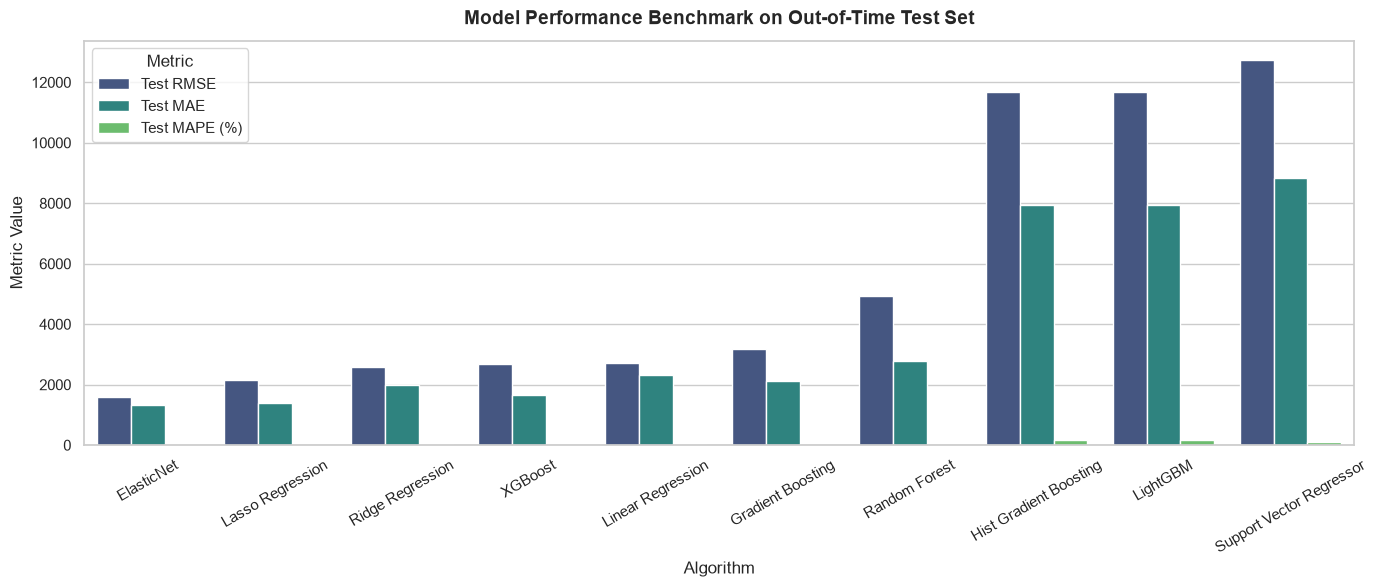

In [6]:
# 1. Benchmark Comparison Bar Chart
fig, ax = src.plot_model_comparison(benchmark_results)
plt.show()

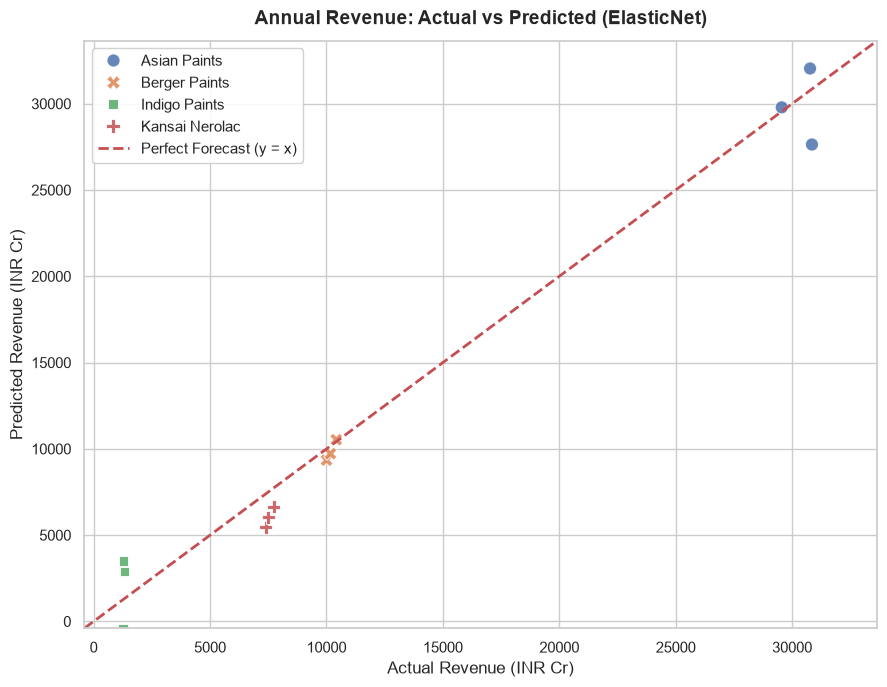

In [7]:
# 2. Actual vs Predicted Scatter Plot for Best Performing Model
best_model_name = benchmark_results.iloc[0]['Model']
best_preds = predictions[best_model_name]

fig, ax = src.plot_actual_vs_predicted(
    y_true=y_test.values,
    y_pred=best_preds,
    company_labels=clean_ann.loc[test_mask, 'company'],
    title=f"Annual Revenue: Actual vs Predicted ({best_model_name})"
)
plt.show()

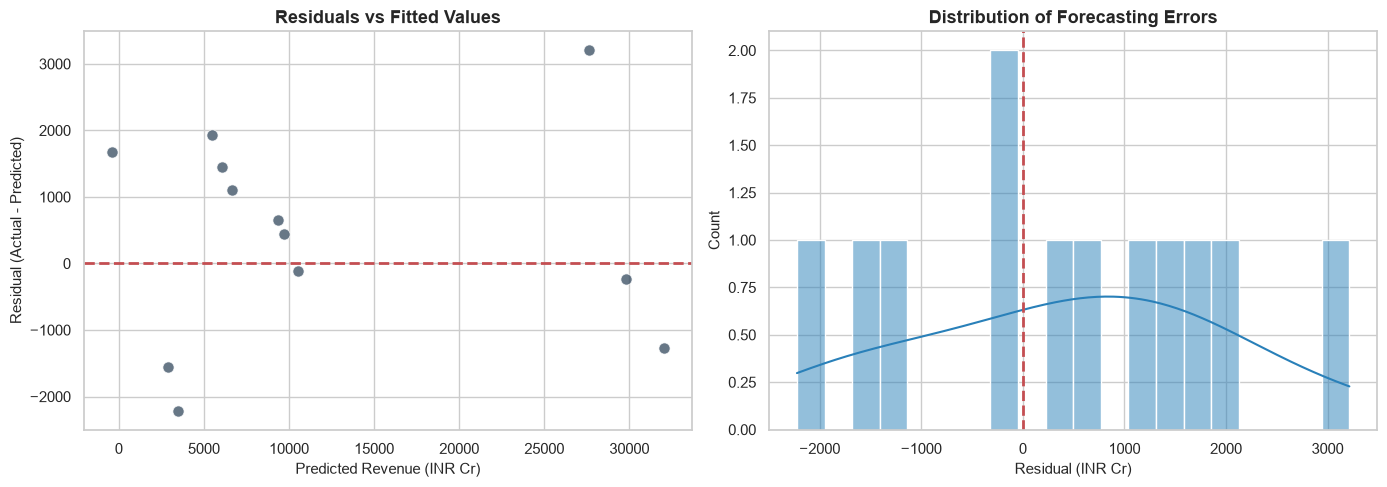

In [8]:
# 3. Residual Error Diagnostics
fig, (ax1, ax2) = src.plot_residuals(
    y_true=y_test.values,
    y_pred=best_preds,
    title=f"Residual Diagnostics ({best_model_name})"
)
plt.show()

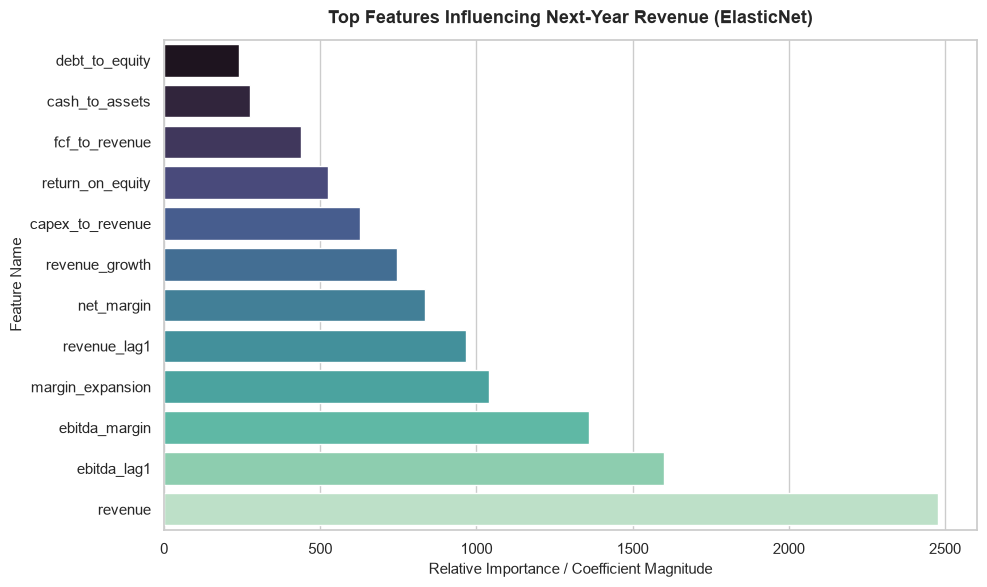

In [9]:
# 4. Feature Importance Analysis
importance_df = src.get_feature_importances(fitted_models[best_model_name], all_ann_cols)
if not importance_df.empty:
    fig, ax = src.plot_feature_importances(
        importance_df, top_n=12, title=f"Top Features Influencing Next-Year Revenue ({best_model_name})"
    )
    plt.show()
else:
    rf_imp = src.get_feature_importances(fitted_models['Random Forest'], all_ann_cols)
    fig, ax = src.plot_feature_importances(rf_imp, top_n=12, title="Random Forest Feature Importances")
    plt.show()

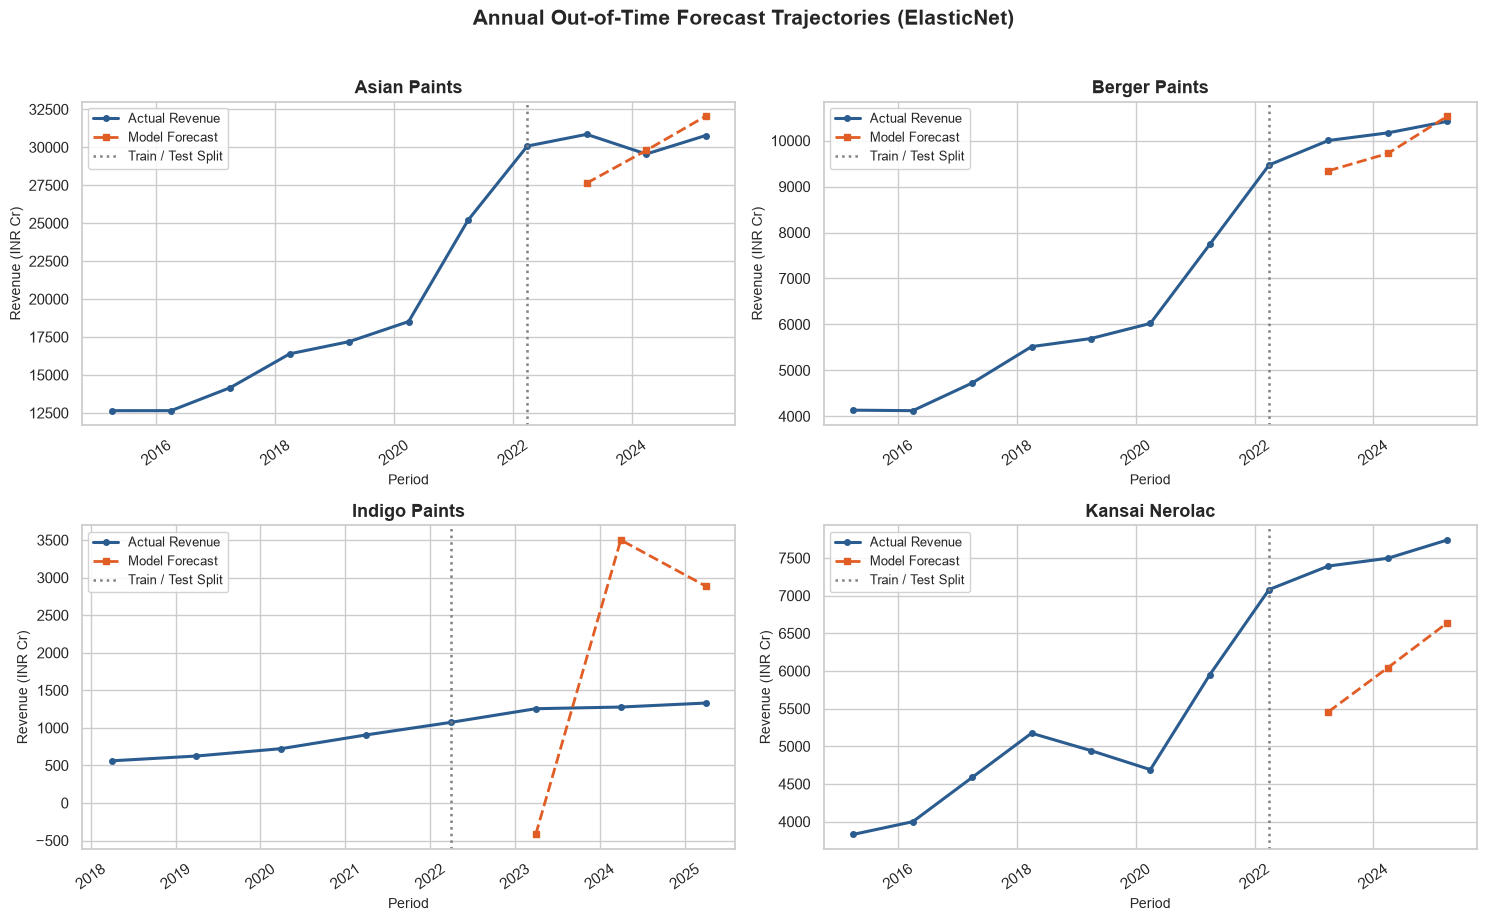

In [10]:
# 5. Out-of-Time Revenue Trajectories by Company
df_eval = clean_ann.copy()
df_eval['predicted_revenue'] = np.nan
df_eval.loc[test_mask, 'predicted_revenue'] = best_preds

fig, axes = src.plot_revenue_trajectories(
    df_eval,
    date_col='period_end',
    actual_col='target_next_revenue',
    pred_col='predicted_revenue',
    company_col='company',
    split_date='2022-03-31',
    title=f"Annual Out-of-Time Forecast Trajectories ({best_model_name})"
)
plt.show()

## 6. Forward Forecast: Predicting FY2027 Revenue
Using the latest audited FY2026 operational and financial data, we generate the out-of-sample forward prediction for **FY2027 Revenue** for each company.

In [11]:
# Prepare latest FY2026 data where target is out-of-sample (NaN)
latest_annual = df_ann_feat.groupby('company').tail(1).copy()
X_latest, _, _, _ = src.prepare_feature_matrix(
    latest_annual, feature_cols=feature_cols, target_col="target_next_revenue", drop_na_target=False
)

best_model = fitted_models[best_model_name]
latest_annual['forecast_FY2027_revenue'] = best_model.predict(X_latest)
latest_annual['implied_growth_%'] = (
    (latest_annual['forecast_FY2027_revenue'] - latest_annual['revenue']) / latest_annual['revenue'] * 100.0
)

print("=== OUT-OF-SAMPLE FY2027 REVENUE FORECAST (INR CRORE) ===")
latest_annual[['company', 'financial_year', 'revenue', 'forecast_FY2027_revenue', 'implied_growth_%']]

=== OUT-OF-SAMPLE FY2027 REVENUE FORECAST (INR CRORE) ===


,company,financial_year,revenue,forecast_FY2027_revenue,implied_growth_%
11,Asian Paints,FY2026,30769.48,30363.863176,-1.318244
23,Berger Paints,FY2026,10420.10,10879.221004,4.406109
32,Indigo Paints,FY2026,1330.12,3166.911721,138.092181
44,Kansai Nerolac,FY2026,7739.23,6604.097008,-14.667260
